In [ ]:
# Sensitivity to Axis Orientation

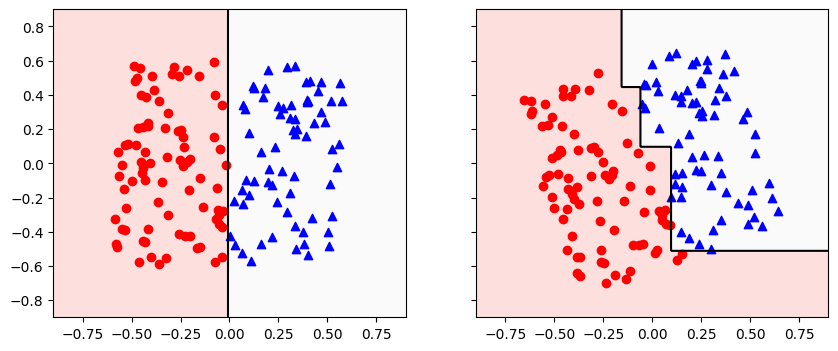

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(seed=42)
X = rng.uniform(-0.6, 0.6, (150, 2))
y = X[:, 0] > 0

def draw(ax, reg, _x, _y):
    reg.fit(_x, _y.astype(int))

    # сетка по обеим осям
    g = np.linspace(-0.9, 0.9, 300)
    xx, yy = np.meshgrid(g, g)
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    pred = reg.predict(grid).reshape(xx.shape)

    # фон и линия границы
    ax.contourf(xx, yy, pred, levels=[-0.5, 0.5, 1.5], colors=["#fde0dd", "#fafafa"])
    ax.contour(xx, yy, pred, levels=[0.5], colors="black")

    ax.scatter(_x[~_y, 0], _x[~_y, 1], c="red", marker="o")
    ax.scatter(_x[_y, 0], _x[_y, 1], c="blue", marker="^")

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)

# Left
draw(ax1, DecisionTreeRegressor(random_state=42), X, y)

# Right
angle = np.deg2rad(20)
R = np.array([[np.cos(angle), -np.sin(angle)],
              [np.sin(angle),  np.cos(angle)]])
X_rot = X @ R.T
draw(ax2, DecisionTreeRegressor(random_state=42), X_rot, y)

plt.show()

[-0.9111246  -2.          0.75787246 -2.         -2.        ]


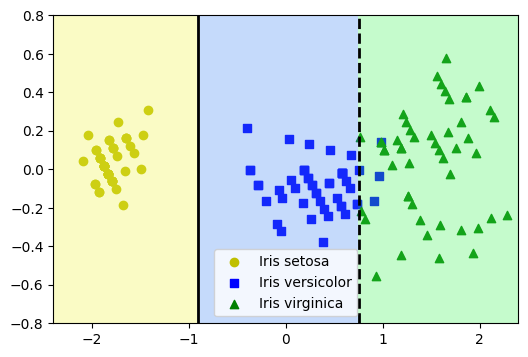

In [99]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

iris = load_iris(as_frame=True)
X_iris = iris.data[["petal length (cm)", "petal width (cm)"]].values
y_iris = iris.target

pca_pipeline = make_pipeline(StandardScaler(), PCA())
X_iris_rotated = pca_pipeline.fit_transform(X_iris)
# X_iris_rotated[:, 0]  →  z1   (горизонталь)
# X_iris_rotated[:, 1]  →  z2   (вертикаль)
tree_clf_pca = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf_pca.fit(X_iris_rotated, y_iris)

# Draw
z1 = X_iris_rotated[:, 0]
z2 = X_iris_rotated[:, 1]
plt.figure(figsize=(6, 4))

plt.scatter(
    z1[y_iris == 0], z2[y_iris == 0], c="y", marker="o", label="Iris setosa"
)  # Рисуем Iris по z1, z2 точкам
plt.scatter(
    z1[y_iris == 1], z2[y_iris == 1], c="b", marker="s", label="Iris versicolor"
)  # Рисуем versicolor по z1, z2 точкам
plt.scatter(
    z1[y_iris == 2], z2[y_iris == 2], c="g", marker="^", label="Iris virginica"
)  # Рисуем virginica по z1, z2 точкам


# Закрашивание фона
g1 = np.linspace(-2.4, 2.4, 200)  # по z1 , границы по  x
g2 = np.linspace(-0.8, 0.8, 200)  # по z2, границы по  y
xx, yy = np.meshgrid(g1, g2)
grid = np.column_stack([xx.ravel(), yy.ravel()])  # 40000,2
pred = tree_clf_pca.predict(grid).reshape(xx.shape)  # (200,200), числа 0/1/2
plt.contourf(
    xx,
    yy,
    pred,
    alpha=0.3,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=["#eff542", "#4287f5", "#42f557"],
)
# Дерево хранит все пороги внутри себя:
# tree_clf_pca.tree_.threshold
# Но там число на каждый узел, а листья хранят мусор (-2). Тебе нужны два конкретных узла:
# узел 0 = корень            → первый разрез   (z1 < −0.911)
# узел 2 = правый ребёнок    → второй разрез   (z1 >  0.758)
# В sklearn: если узел делится, его левый ребёнок = 1, правый = 2. Поэтому [[0, 2]].
# Границы
print(tree_clf_pca.tree_.threshold)
th0, th1 = tree_clf_pca.tree_.threshold[[0, 2]]

plt.axvline(th0, color="k", linewidth=2)                  # сплошная
plt.axvline(th1, color="k", linewidth=2, linestyle="--")   # пунктир

plt.legend()
plt.show()
